<div style="text-align: center; font-style: italic; font-size: 18px">Water Resources Management</div>
<div></div>
<div style="text-align: center">Supplementary Information of</div>
<div style="text-align: center; font-weight: bold; font-size: 24px">Data-Driven Leak Localization Modeling for Optimal Sensor Placement</div>

---

Maria Gloria Di Chiano<sup>1*</sup>, Dennis Zanutto<sup>2,3</sup>, Gianfranco Becciu<sup>1</sup>, Dragan Savić<sup>3,4</sup>

<sup>1</sup>D.I.C.A. Politecnico di Milano, 20133 Milano, Italy

<sup>2</sup>D.E.I.B, Politecnico di Milano, 20133, Milano, Italy

<sup>3</sup>KWR Water Research Institute, Nieuwegein, 3430 BB, the Netherlands

<sup>4</sup>Centre for Water Systems, University of Exeter, Exeter, EX4 4QF, United Kingdom


## Content of this File

- Text S4.1
- Text S4.2
- Text S4.3

## Introduction
This notebook tests the nearest-sensor clustering method for reconstructing the Leak Signature Matrix (LSM).

In [1]:
# Imports
from wdn_osp_ll.sensor_placement_optimization import load_or_compute
from wdn_osp_ll.visualization import (
    plot_pareto_front_nsensors_msa,
    plot_hypervolume_bar,
    plot_hypervolume_trajectory,
)

## Text S4

### S4.1 — Alternative Distance Metrics

The goal of this comparison is to test different distance metrics when performing the node clustering around the sensors. 
We test topological distance, pipe length and pipe hydraulic resistance.

In [2]:
topo_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "sensitivity",
            "scale_nodes_by_scenario_mean": False,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "topological",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

topo_res = load_or_compute(config=topo_cfg)

Starting optimisation...
[2026-11-06 15:37:14] generation      0 | best hypervolume: 127.806452 | median: 108.774194
[2026-11-06 15:37:15] generation     10 | best hypervolume: 293.225806 | median: 274.951613
[2026-11-06 15:37:16] generation     20 | best hypervolume: 303.806452 | median: 295.112903
[2026-11-06 15:37:16] generation     30 | best hypervolume: 308.870968 | median: 297.032258
[2026-11-06 15:37:17] generation     40 | best hypervolume: 309.870968 | median: 299.596774
[2026-11-06 15:37:17] generation     50 | best hypervolume: 310.225806 | median: 300.145161
[2026-11-06 15:37:17] generation     60 | best hypervolume: 310.838710 | median: 301.629032
[2026-11-06 15:37:17] generation     70 | best hypervolume: 311.096774 | median: 302.080645
[2026-11-06 15:37:17] generation     80 | best hypervolume: 311.225806 | median: 302.677419
[2026-11-06 15:37:18] generation     90 | best hypervolume: 311.387097 | median: 302.709677
[2026-11-06 15:37:18] generation    100 | best hypervol

In [3]:
length_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "sensitivity",
            "scale_nodes_by_scenario_mean": False,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

length_undir_res = load_or_compute(config=length_cfg)

Starting optimisation...
[2026-11-06 15:37:18] generation      0 | best hypervolume: 200.258065 | median: 132.516129
[2026-11-06 15:37:18] generation     10 | best hypervolume: 293.903226 | median: 281.693548
[2026-11-06 15:37:19] generation     20 | best hypervolume: 312.741935 | median: 304.774194
[2026-11-06 15:37:19] generation     30 | best hypervolume: 316.096774 | median: 308.806452
[2026-11-06 15:37:19] generation     40 | best hypervolume: 317.290323 | median: 312.096774
[2026-11-06 15:37:19] generation     50 | best hypervolume: 317.354839 | median: 314.419355
[2026-11-06 15:37:20] generation     60 | best hypervolume: 317.419355 | median: 314.435484
[2026-11-06 15:37:20] generation     70 | best hypervolume: 318.161290 | median: 314.580645
[2026-11-06 15:37:20] generation     80 | best hypervolume: 318.161290 | median: 314.645161
[2026-11-06 15:37:20] generation     90 | best hypervolume: 318.290323 | median: 315.419355
[2026-11-06 15:37:20] generation    100 | best hypervol

In [4]:
resis_undir_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "sensitivity",
            "scale_nodes_by_scenario_mean": False,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "resistance",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

resis_undir_res = load_or_compute(config=resis_undir_cfg)

Starting optimisation...
[2026-11-06 15:37:21] generation      0 | best hypervolume: 146.709677 | median: 97.387097
[2026-11-06 15:37:21] generation     10 | best hypervolume: 258.516129 | median: 244.548387
[2026-11-06 15:37:21] generation     20 | best hypervolume: 289.225806 | median: 274.790323
[2026-11-06 15:37:21] generation     30 | best hypervolume: 296.774194 | median: 277.451613
[2026-11-06 15:37:22] generation     40 | best hypervolume: 297.000000 | median: 277.758065
[2026-11-06 15:37:22] generation     50 | best hypervolume: 298.064516 | median: 278.387097
[2026-11-06 15:37:22] generation     60 | best hypervolume: 298.709677 | median: 278.564516
[2026-11-06 15:37:22] generation     70 | best hypervolume: 300.419355 | median: 278.564516
[2026-11-06 15:37:23] generation     80 | best hypervolume: 301.838710 | median: 278.564516
[2026-11-06 15:37:23] generation     90 | best hypervolume: 302.032258 | median: 278.564516
[2026-11-06 15:37:23] generation    100 | best hypervolu

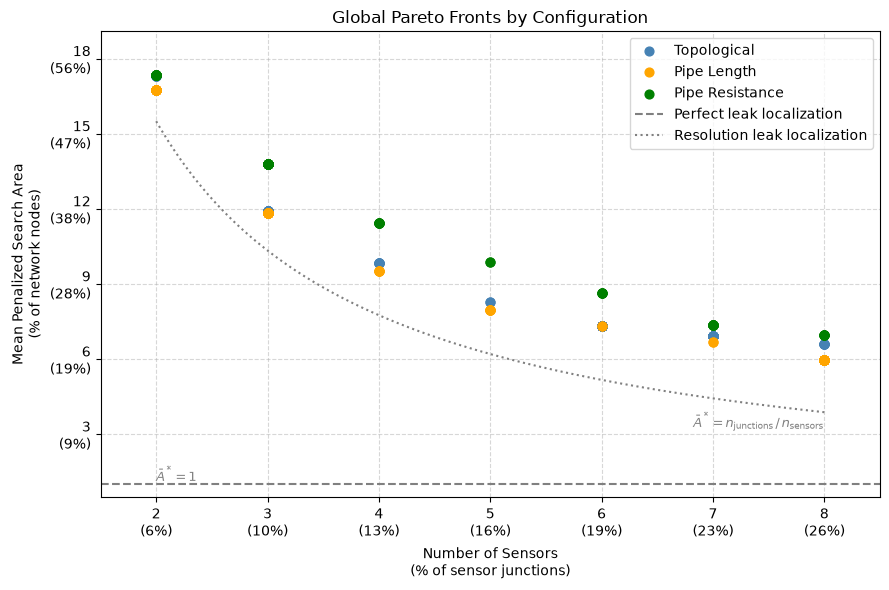

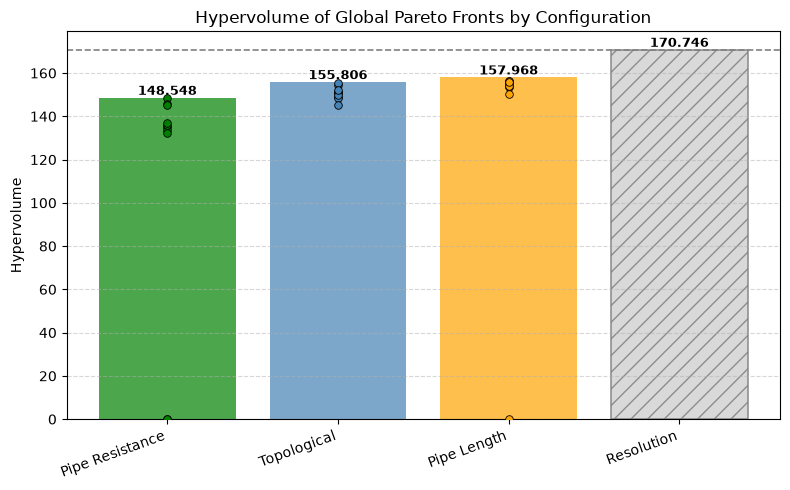

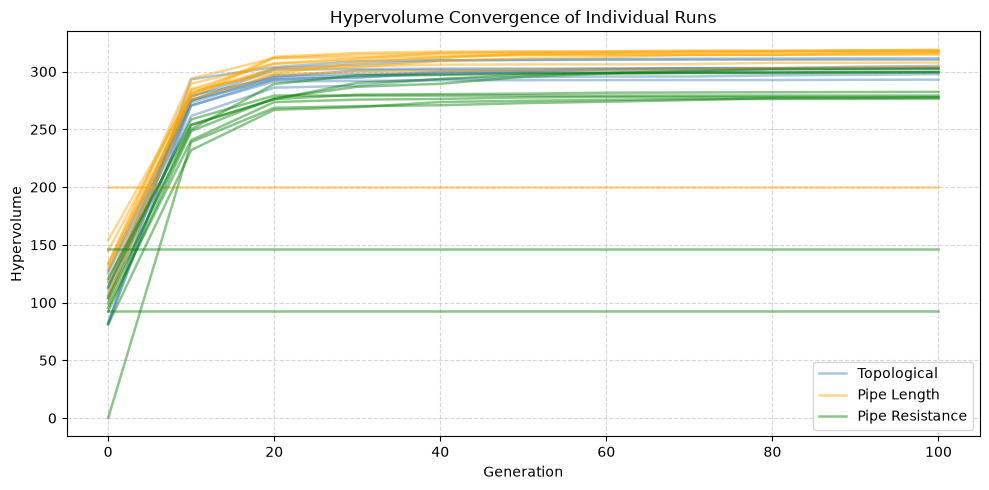

In [5]:
results = [topo_res, length_undir_res, resis_undir_res]
labels = ["Topological", "Pipe Length", "Pipe Resistance"]
colors = ["steelblue", "orange", "green"]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results** Using pipe length as the distance metric works slightly better than using the topological distance. However, using the hydraulic resistance of the pipes to compute the minimum distance path along the network performs significantly worse. 

### S4.2 — Impact of Scenario-based Scaling and Choice of the Leak Signature Matrix

The goal of this comparison is to test if the nearest-sensor clustering also beneftis from using the chi-squared as LSM instead of the Sensitivity Matrix, or if, differently from Boatwright et al. and Alves et al. reconstruction techniques, this decision does not affect the methodology. 

In [6]:
scaled_chisq_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": 14.5,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

scaled_chisq_res = load_or_compute(config=scaled_chisq_cfg)

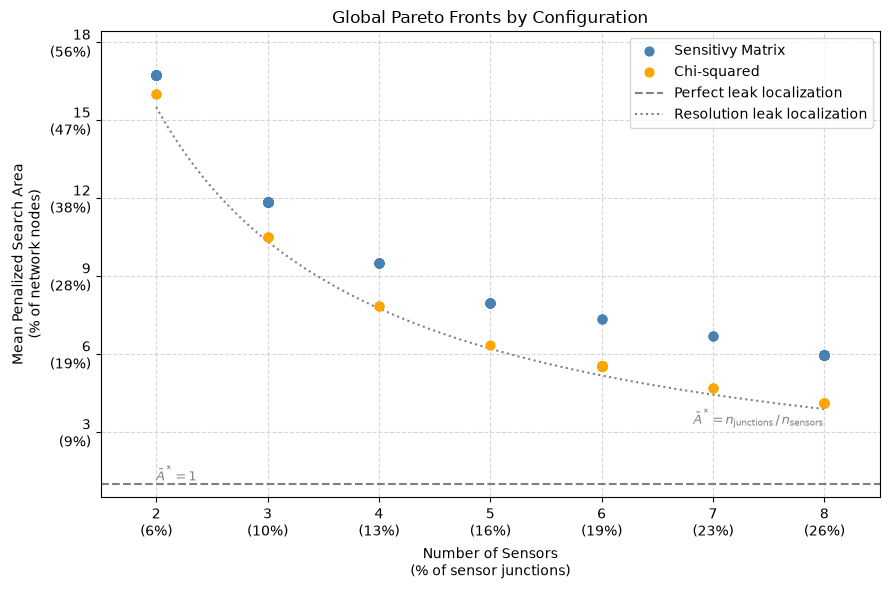

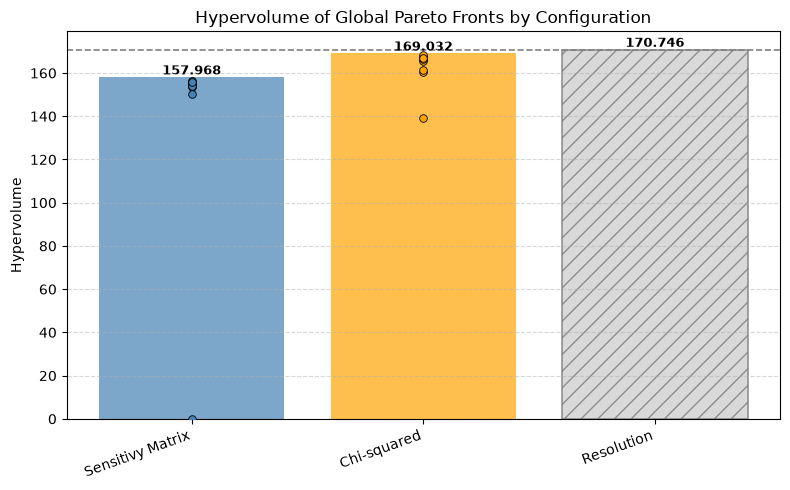

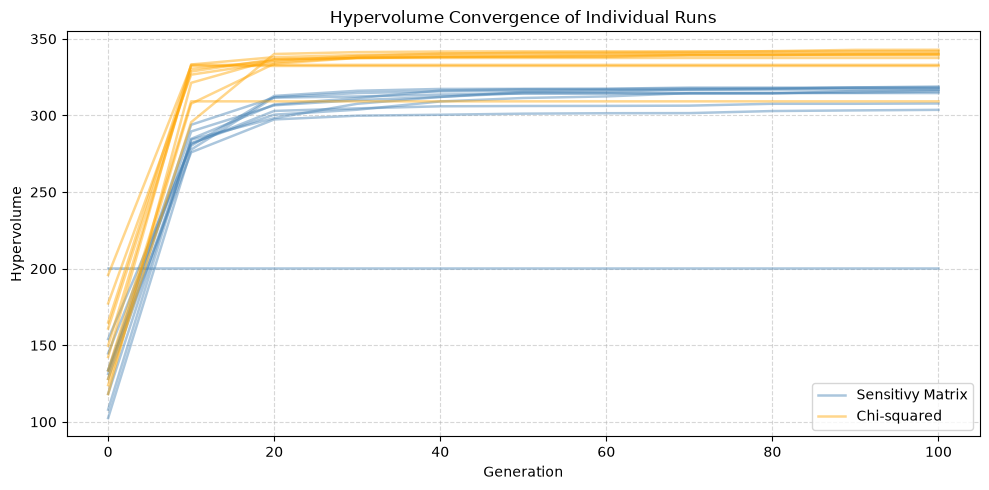

In [7]:
results = [length_undir_res, scaled_chisq_res]
labels = ["Sensitivy Matrix", "Chi-squared"]
colors = ["steelblue", "orange", "green"]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** As for the Boatwright et al. and Alves et al. reconstruction methods, using the Scaled Chi-squared as LSM enables better leak localization performance.

### S4.3 — Impact of Directed vs Undirected Graph

The goal of this comparison is to test if for this reconstruction method calculating distances over a directed graph can improve the leak localization perfromance with respect to doing it on an undirected graph.
This has not proved helpful for Boatwright and Alves reconstruction methods neither.

In [8]:
directed_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": True,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

directed_res = load_or_compute(config=directed_cfg)

Starting optimisation...
[2026-11-06 15:37:24] generation      0 | best hypervolume: 194.816129 | median: 154.800000
[2026-11-06 15:37:24] generation     10 | best hypervolume: 323.729032 | median: 319.679032
[2026-11-06 15:37:25] generation     20 | best hypervolume: 334.061290 | median: 328.917742
[2026-11-06 15:37:25] generation     30 | best hypervolume: 335.387097 | median: 330.719355
[2026-11-06 15:37:25] generation     40 | best hypervolume: 336.600000 | median: 331.822581
[2026-11-06 15:37:26] generation     50 | best hypervolume: 336.922581 | median: 333.014516
[2026-11-06 15:37:26] generation     60 | best hypervolume: 337.116129 | median: 333.258065
[2026-11-06 15:37:26] generation     70 | best hypervolume: 337.490323 | median: 333.596774
[2026-11-06 15:37:27] generation     80 | best hypervolume: 337.709677 | median: 334.041935
[2026-11-06 15:37:27] generation     90 | best hypervolume: 337.709677 | median: 334.303226
[2026-11-06 15:37:27] generation    100 | best hypervol

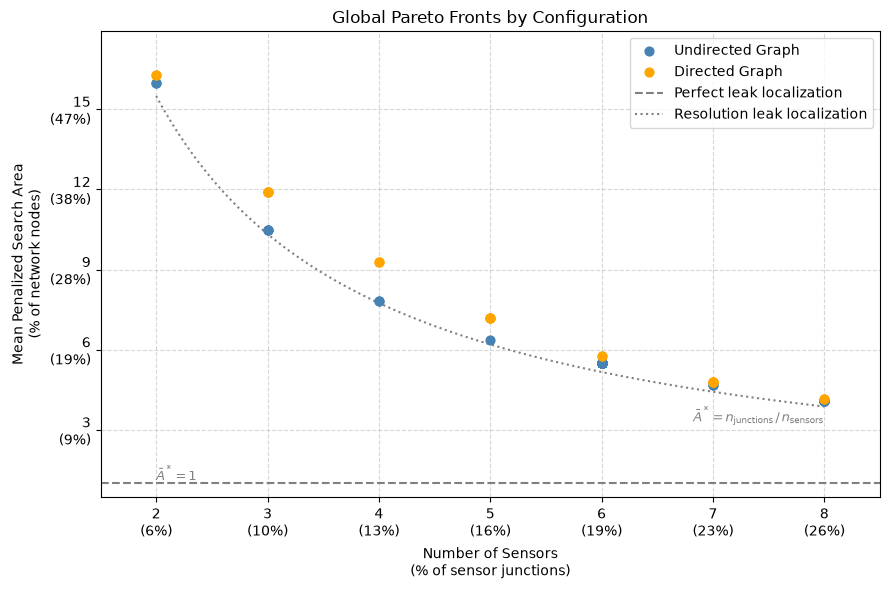

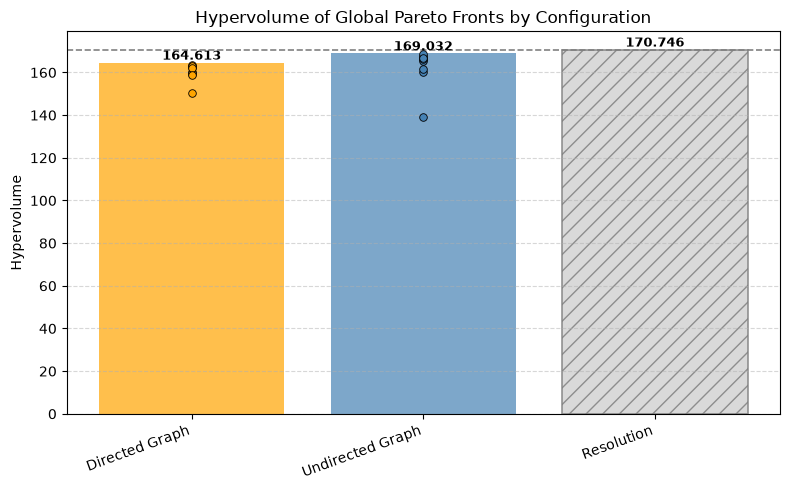

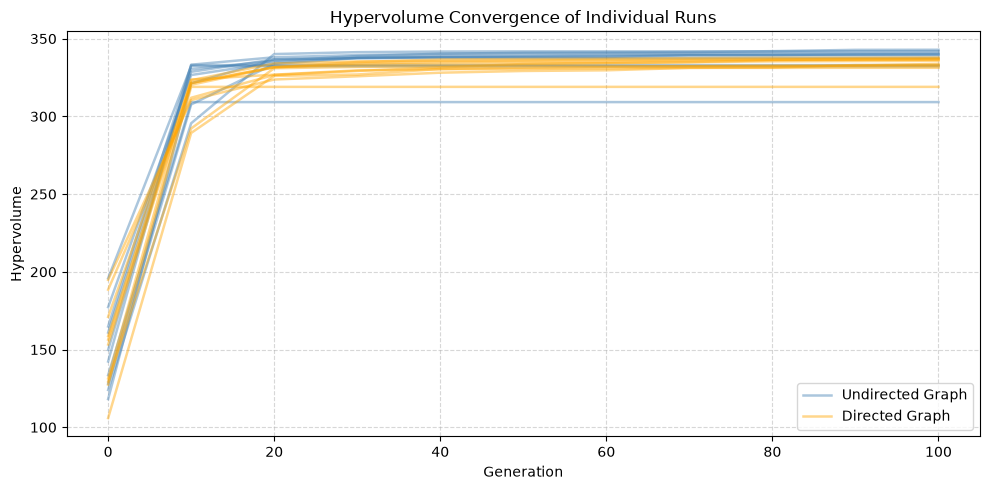

In [9]:
results = [scaled_chisq_res, directed_res]
labels = ["Undirected Graph", "Directed Graph"]
colors = ["steelblue", "orange", "green"]

# 1. Pareto front scatter (x=obj 0, y=obj 1 by default)
fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)

# 2. Parallel coordinates of all objectives (normalised to [0,1])
#fig, ax = plot_parallel_coordinates(results, labels, colors)

# 3. Hypervolume bar — max HV across islands at final generation
fig, ax = plot_hypervolume_bar(results, labels, colors)

# 4a. Hypervolume per island across generations
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** This experiments conferms the observation of the other experiments: calculating distances over an undirected graph offers marginally higher performance than using a direct graph.